In [84]:
%pip install scikit-learn scipy seaborn pandas numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\USUARIO\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [85]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import DBSCAN
from sklearn.metrics import confusion_matrix, roc_auc_score, RocCurveDisplay
from sklearn.inspection import permutation_importance

os.makedirs("outputs", exist_ok=True)
SEED = 42
R = 6371                          # radio de la Tierra (km)

# Parámetros de DBSCAN elegidos en la Parte A
EPS_M, MIN_SAMPLES = 150, 1000

N_TRAIN = 40_000
MAX_TEST = 100_000                # tope de filas de prueba (por velocidad del KNN)

# Parte B: aprendizaje supervisado (predecir)

# 1. Definición


Fechas que no se pudieron leer: 0


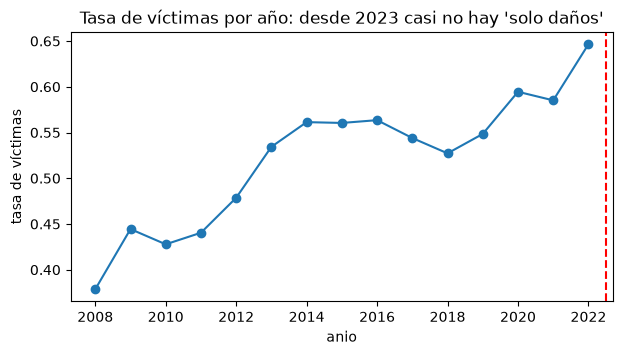

Filas: 636,659 -> 598,935


In [86]:
df = pd.read_csv("Fatal_Road_Traffic.csv", sep=";", decimal=",",
                 na_values=["N/D", "Sin inf"], low_memory=False)

# Fecha: viene como 01/ene/2008 (mes en español); se lleva a número con un mapa
meses = {"ene": "01", "feb": "02", "mar": "03", "abr": "04", "may": "05", "jun": "06",
         "jul": "07", "ago": "08", "sep": "09", "oct": "10", "nov": "11", "dic": "12"}
fecha_txt = df["FECHA_INCIDENTE"].astype(str).str.strip().str.lower()
for es, num in meses.items():
    fecha_txt = fecha_txt.str.replace("/" + es + "/", "/" + num + "/", regex=False)
df["fecha"] = pd.to_datetime(fecha_txt, format="%d/%m/%Y", errors="coerce")
print("Fechas que no se pudieron leer:", df["fecha"].isna().sum())     # debe ser 0

df["hora"] = pd.to_numeric(df["HORA_INCIDENTE"].astype(str).str.split(":").str[0], errors="coerce")
df["dia_semana"] = df["fecha"].dt.dayofweek
df["mes"] = df["fecha"].dt.month
df["anio"] = df["fecha"].dt.year
df["fin_de_semana"] = (df["dia_semana"] >= 5).astype(int)
df = df[df["anio"] <= 2022].copy()  

# Variable objetivo
g = df["GRAVEDAD_INCIDENTE"].astype(str).str.lower()
df["con_victimas"] = np.where(g.str.contains("herid|muert"), 1,
                              np.where(g.str.contains("daño|dano"), 0, np.nan))

df = df.rename(columns={"Latitud": "lat", "Longitud": "lon", "CLASE_INCIDENTE": "clase",
                        "Comuna Planeacion": "comuna"})
for c in ["lat", "lon"]:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", "."), errors="coerce")

# Misma limpieza de la Parte A
n0 = len(df)
df = df.dropna(subset=["lat", "lon", "hora", "con_victimas", "fecha"])
df = df[df["lat"].between(6.08, 6.42) & df["lon"].between(-75.72, -75.45)].reset_index(drop=True)
df["comuna"] = df["comuna"].fillna("Sin dato")          
df["con_victimas"] = df["con_victimas"].astype(int)

tasa_anio = df.groupby("anio")["con_victimas"].mean()
ax = tasa_anio.plot(marker="o", figsize=(7, 3.5))
ax.axvline(2022.5, color="red", ls="--"); ax.set_ylabel("tasa de víctimas")
ax.set_title("Tasa de víctimas por año: desde 2023 casi no hay 'solo daños'")
plt.savefig("outputs/B0_tasa_por_anio.png", dpi=150, bbox_inches="tight"); plt.show()
df = df[df["anio"] <= 2022].copy()

print(f"Filas: {n0:,} -> {len(df):,}")

## Balance de clases


con_victimas
1    314194
0    284741
Name: count, dtype: int64
con_victimas
1    0.525
0    0.475
Name: proportion, dtype: float64

Tasa de víctimas por clase de incidente:
                  size   mean
clase                        
Choque          412407  0.315
Incendio            78  0.590
Volcamiento      16629  0.965
Otro             62637  0.975
Atropello        60764  1.000
Caida Ocupante   46420  1.000


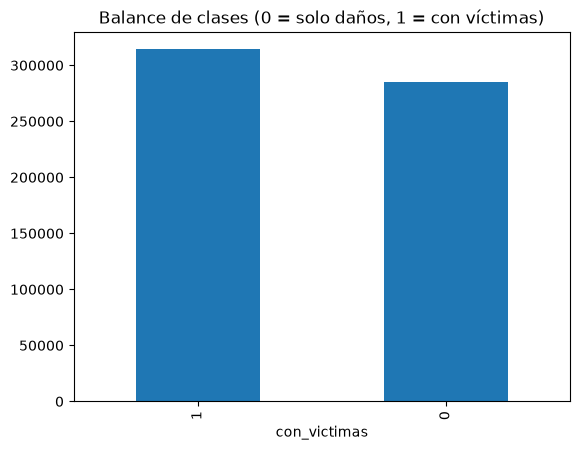

In [87]:
print(df["con_victimas"].value_counts())
print(df["con_victimas"].value_counts(normalize=True).round(3))
print("\nTasa de víctimas por clase de incidente:")
print(df.groupby("clase")["con_victimas"].agg(["size", "mean"]).round(3).sort_values("mean"))
df["con_victimas"].value_counts().plot.bar(); plt.title("Balance de clases (0 = solo daños, 1 = con víctimas)")
plt.savefig("outputs/B1_balance.png", dpi=150); plt.show()

# 2. Partición de los datos y prevención de fuga
entrenamiento = 2008-2022. Simula el uso real (se predice el futuro con lo aprendido del pasado) y es más exigente que una partición aleatoria.

DBSCAN se ajusta solo con el train y a cada incidente se le calcula su distancia al punto núcleo más cercano. DBSCAN no usa la variable objetivo, así que no hay fuga de la respuesta.


In [88]:
# Variables derivadas (hora, día y mes son circulares: seno y coseno)
df["hora_sin"], df["hora_cos"] = np.sin(2 * np.pi * df["hora"] / 24), np.cos(2 * np.pi * df["hora"] / 24)
df["dia_sin"], df["dia_cos"] = np.sin(2 * np.pi * df["dia_semana"] / 7), np.cos(2 * np.pi * df["dia_semana"] / 7)
df["mes_sin"], df["mes_cos"] = np.sin(2 * np.pi * df["mes"] / 12), np.cos(2 * np.pi * df["mes"] / 12)

# Hotspots (Parte A)
df["lat_r"], df["lon_r"] = df["lat"].round(4), df["lon"].round(4)
train_full = df[df["anio"] <= 2020]
pt = train_full.groupby(["lat_r", "lon_r"]).size().rename("w").reset_index()
ct = np.radians(pt[["lat_r", "lon_r"]].to_numpy())
eps_rad = (EPS_M / 1000) / R
db = DBSCAN(eps=eps_rad, min_samples=MIN_SAMPLES, metric="haversine", algorithm="ball_tree")
db.fit(ct, sample_weight=pt["w"])
nucleos = ct[db.core_sample_indices_]
print(f"Puntos núcleo en train: {len(nucleos):,} | hotspots: {len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)}")

if len(nucleos):
    nn = NearestNeighbors(n_neighbors=1, metric="haversine", algorithm="ball_tree").fit(nucleos)
    dist, _ = nn.kneighbors(np.radians(df[["lat", "lon"]].to_numpy()))
    df["dist_hotspot_km"] = np.minimum(dist[:, 0] * R, 5.0)       # distancia al hotspot más cercano (tope 5 km)
else:
    df["dist_hotspot_km"] = 5.0
df["en_hotspot"] = (df["dist_hotspot_km"] <= EPS_M / 1000).astype(int)
print("% de incidentes en hotspot (todo el dataset):", round(df["en_hotspot"].mean(), 3))

Puntos núcleo en train: 1,108 | hotspots: 75
% de incidentes en hotspot (todo el dataset): 0.502


In [89]:
tiempo = ["hora_sin", "hora_cos", "dia_sin", "dia_cos", "mes_sin", "mes_cos", "fin_de_semana"]
lugar_num = ["lat", "lon"]
hotspot = ["en_hotspot", "dist_hotspot_km"]
num_cols = tiempo + lugar_num + hotspot
cat_cols = ["clase", "comuna"]

train = df[df["anio"] <= 2020]
test = df[df["anio"] >= 2021]
print(f"Train completo: {len(train):,} | Test completo: {len(test):,}")

tr = train.sample(min(N_TRAIN, len(train)), random_state=SEED)
te = test.sample(min(MAX_TEST, len(test)), random_state=SEED)
X_train, y_train = tr[num_cols + cat_cols], tr["con_victimas"]
X_test, y_test = te[num_cols + cat_cols], te["con_victimas"]

print("Tasa de víctimas -> train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)

Train completo: 522,862 | Test completo: 76,073
Tasa de víctimas -> train: 0.505 | test: 0.615


# 3. Modelo de referencia (baseline)
Predecir siempre la clase mayoritaria. Cualquier modelo debe superarlo para que valga la pena.

In [90]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
acc_base = baseline.score(X_test, y_test)
print(f"Baseline: exactitud en prueba = {acc_base:.3f} (siempre predice la clase mayoritaria)")
print("Sensibilidad = 1 y especificidad = 0 si la mayoritaria es 'con víctimas'; AUC = 0.5")

Baseline: exactitud en prueba = 0.615 (siempre predice la clase mayoritaria)
Sensibilidad = 1 y especificidad = 0 si la mayoritaria es 'con víctimas'; AUC = 0.5


# 4. Modelos

In [91]:
def hacer_prep(num, cat):
    pasos = []
    if num: pasos.append(("num", StandardScaler(), num))
    if cat: pasos.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return ColumnTransformer(pasos)

def con_prep(clf):
    return Pipeline([("prep", hacer_prep(num_cols, cat_cols)), ("clf", clf)])

t0 = time.time()
# Elegir K del KNN y la profundidad del árbol con validación cruzada
gs_knn = GridSearchCV(con_prep(KNeighborsClassifier()), {"clf__n_neighbors": [15, 45, 101]},
                      cv=cv3, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
gs_tree = GridSearchCV(con_prep(DecisionTreeClassifier(min_samples_leaf=50, random_state=SEED)),
                       {"clf__max_depth": [3, 5, 8, 12]}, cv=cv3, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print("KNN  mejor K:", gs_knn.best_params_, "| AUC CV por K:", gs_knn.cv_results_["mean_test_score"].round(3))
print("Árbol mejor profundidad:", gs_tree.best_params_, "| AUC CV por prof.:", gs_tree.cv_results_["mean_test_score"].round(3))
print(f"({time.time() - t0:.0f} s)")

KNN  mejor K: {'clf__n_neighbors': 45} | AUC CV por K: [0.799 0.808 0.803]
Árbol mejor profundidad: {'clf__max_depth': 8} | AUC CV por prof.: [0.821 0.834 0.838 0.833]
(31 s)


In [ ]:
modelos = {
    "Logística": con_prep(LogisticRegression(max_iter=1000)),
    "KNN": gs_knn.best_estimator_,
    "Árbol": gs_tree.best_estimator_,
    "Random Forest": con_prep(RandomForestClassifier(n_estimators=300, max_features="sqrt",
                                                      min_samples_leaf=20, n_jobs=-1, random_state=SEED)),
    "Gradient Boosting": con_prep(GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                                              max_depth=3, random_state=SEED)),
    "MLP (32,16)": con_prep(MLPClassifier(hidden_layer_sizes=(32, 16), early_stopping=True,
                                          max_iter=300, random_state=SEED)),
}

# AUC en validación cruzada (5 partes) dentro del train: con esto se COMPARA y se ELIGE, no con la prueba
cv_auc = {}
for nombre, m in modelos.items():
    t0 = time.time()
    cv_auc[nombre] = cross_val_score(m, X_train, y_train, cv=cv5, scoring="roc_auc").mean()
    print(f"{nombre:18s} AUC CV = {cv_auc[nombre]:.3f}   ({time.time() - t0:.0f} s)")

Logística          AUC CV = 0.843   (7 s)
KNN                AUC CV = 0.811   (12 s)
Árbol              AUC CV = 0.838   (3 s)
Random Forest      AUC CV = 0.848   (43 s)


# 5. Evaluación
Con umbral 0.5: matriz de confusión, exactitud, sensibilidad y especificidad de cada modelo, y AUC. Se reporta también el entrenamiento para detectar sobreajuste

In [ ]:
def metricas(y, p, umbral=0.5):
    pred = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(exactitud=(tp + tn) / len(y), sensibilidad=tp / (tp + fn) if tp + fn else np.nan,
                especificidad=tn / (tn + fp) if tn + fp else np.nan, FN=fn, FP=fp)

todos = {"Baseline": baseline, **modelos}
probs_tr, probs_te, filas = {}, {}, []
for nombre, m in todos.items():
    if nombre != "Baseline":
        m.fit(X_train, y_train)
    probs_tr[nombre] = m.predict_proba(X_train)[:, 1]
    probs_te[nombre] = m.predict_proba(X_test)[:, 1]
    mt, mte = metricas(y_train, probs_tr[nombre]), metricas(y_test, probs_te[nombre])
    filas.append(dict(modelo=nombre, exact_train=mt["exactitud"], exact_test=mte["exactitud"],
                      sensibilidad=mte["sensibilidad"], especificidad=mte["especificidad"],
                      AUC_cv=cv_auc.get(nombre, 0.5), AUC_train=roc_auc_score(y_train, probs_tr[nombre]),
                      AUC_test=roc_auc_score(y_test, probs_te[nombre]), FN=mte["FN"], FP=mte["FP"]))
resultados = pd.DataFrame(filas).set_index("modelo")
resultados["brecha_AUC"] = resultados["AUC_train"] - resultados["AUC_test"]
resultados.round(3)

,exact_train,exact_test,sensibilidad,especificidad,AUC_cv,AUC_train,AUC_test,FN,FP,brecha_AUC
modelo,,,,,,,,,,
Baseline,0.505,0.615,1.000,0.000,0.500,0.500,0.500,0,29292,0.000
Logística,0.788,0.750,0.619,0.959,0.843,0.844,0.835,17812,1203,0.010
KNN,0.754,0.705,0.604,0.866,0.811,0.837,0.800,18533,3931,0.037
Árbol,0.795,0.749,0.641,0.921,0.838,0.856,0.831,16790,2314,0.024
Random Forest,0.799,0.750,0.611,0.972,0.848,0.897,0.839,18214,822,0.057
Gradient Boosting,0.795,0.752,0.629,0.950,0.848,0.863,0.840,17359,1476,0.023
"MLP (32,16)",0.791,0.749,0.642,0.921,0.840,0.852,0.833,16730,2327,0.019


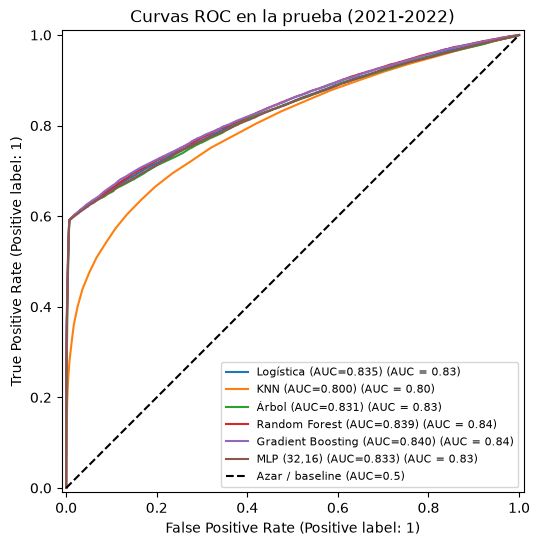

In [ ]:
# Curvas ROC de TODOS los modelos en un mismo gráfico con su AUC
fig, ax = plt.subplots(figsize=(7, 6))
for nombre, p in probs_te.items():
    if nombre == "Baseline":
        continue
    RocCurveDisplay.from_predictions(y_test, p, name=f"{nombre} (AUC={roc_auc_score(y_test, p):.3f})", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Azar / baseline (AUC=0.5)")
ax.set(title="Curvas ROC en la prueba (2021-2022)"); ax.legend(loc="lower right", fontsize=8)
plt.savefig("outputs/B2_roc_todos.png", dpi=150); plt.show()

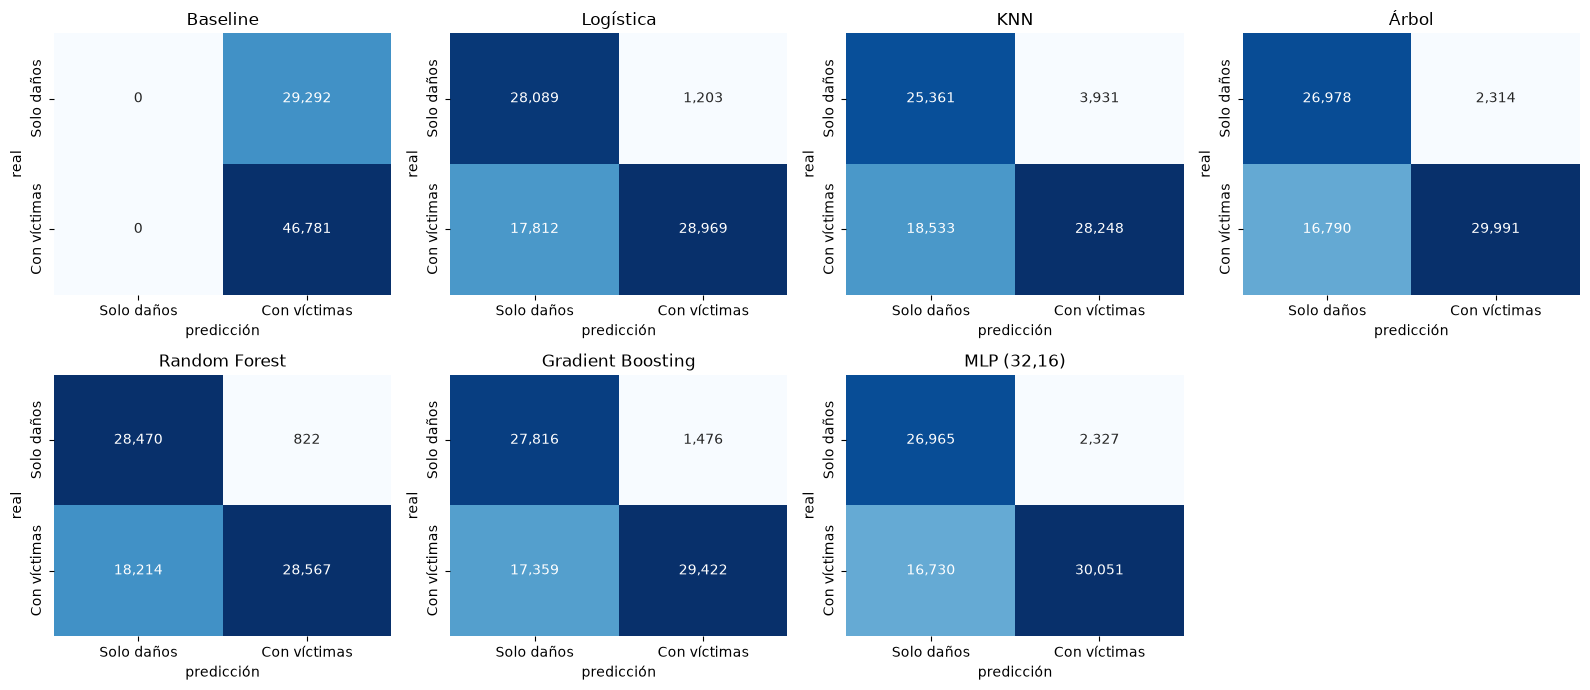

In [ ]:
# Matrices de confusión (filas = real, columnas = predicción), umbral 0.5
fig, axs = plt.subplots(2, 4, figsize=(16, 7)); axs = axs.ravel()
for ax, (nombre, p) in zip(axs, probs_te.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Solo daños", "Con víctimas"], yticklabels=["Solo daños", "Con víctimas"])
    ax.set(title=nombre, xlabel="predicción", ylabel="real")
for ax in axs[len(probs_te):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("outputs/B3_matrices_confusion.png", dpi=150); plt.show()

## Sobreajuste: entrenamiento vs. prueba
Un modelo que rinde mucho en train y bastante menos en la prueba memorizó. La prueba son años futuros, así que la brecha puede mezclar sobreajuste y cambios en el tiempo.

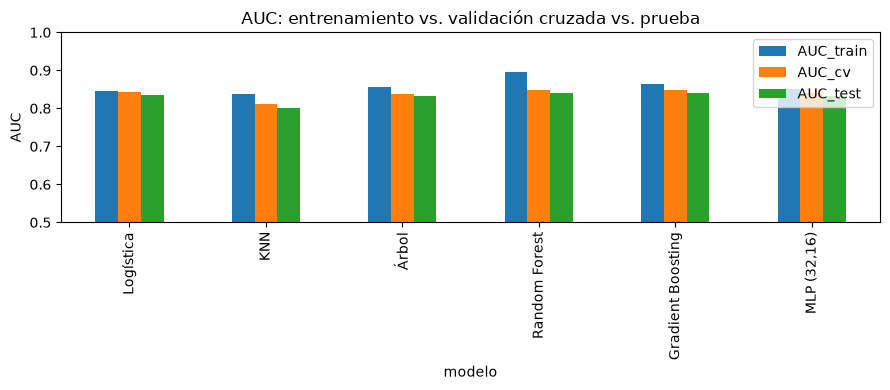

,AUC_train,AUC_cv,AUC_test,brecha_AUC
modelo,,,,
Baseline,0.500,0.500,0.500,0.000
Logística,0.844,0.843,0.835,0.010
KNN,0.837,0.811,0.800,0.037
Árbol,0.856,0.838,0.831,0.024
Random Forest,0.897,0.848,0.839,0.057
Gradient Boosting,0.863,0.848,0.840,0.023
"MLP (32,16)",0.852,0.840,0.833,0.019


In [ ]:
ax = resultados.loc[resultados.index != "Baseline", ["AUC_train", "AUC_cv", "AUC_test"]].plot.bar(figsize=(9, 4))
ax.set(title="AUC: entrenamiento vs. validación cruzada vs. prueba", ylabel="AUC", ylim=(0.5, 1.0))
plt.tight_layout(); plt.savefig("outputs/B4_sobreajuste.png", dpi=150); plt.show()
resultados[["AUC_train", "AUC_cv", "AUC_test", "brecha_AUC"]].round(3)

# 6. Elección del modelo y umbral de decisión
El modelo se elige por AUC de validación cruzada (no por la prueba), considerando también simplicidad e interpretabilidad

 si un falso negativo cuesta `r` veces un falso positivo, el umbral que minimiza el costo se busca con las probabilidades fuera de muestra del train (`cross_val_predict`), y recién después se evalúa en la prueba.
La razón `r` es un supuesto (no hay costos reales)

Mayor AUC de CV: Random Forest (0.848)
Modelo elegido: Logística (0.843), diferencia de 0.005 AUC


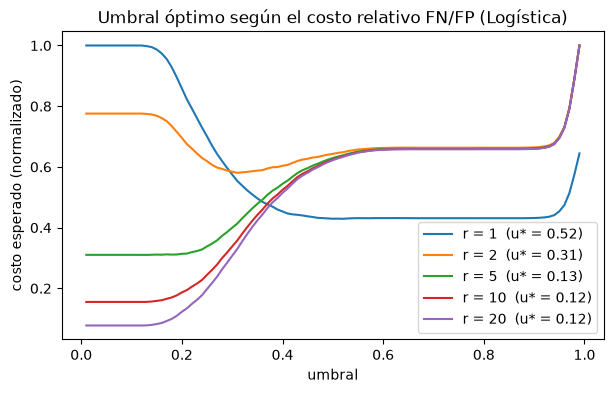

Umbral óptimo por razón de costos: {1: np.float64(0.52), 2: np.float64(0.31), 5: np.float64(0.13), 10: np.float64(0.12), 20: np.float64(0.12)}


In [ ]:
mejor_auc = max(cv_auc, key=cv_auc.get)
mejor = "Logística"   # se elige la más simple porque empata en AUC dentro del ruido
print(f"Mayor AUC de CV: {mejor_auc} ({cv_auc[mejor_auc]:.3f})")
print(f"Modelo elegido: {mejor} ({cv_auc[mejor]:.3f}), diferencia de {cv_auc[mejor_auc] - cv_auc[mejor]:.3f} AUC")

oof = cross_val_predict(modelos[mejor], X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
yv = y_train.to_numpy()
umbrales = np.linspace(0.01, 0.99, 99)

def costo(y, p, u, r):
    pred = p >= u
    fn = ((~pred) & (y == 1)).sum()
    fp = (pred & (y == 0)).sum()
    return (r * fn + fp) / len(y)

razones = [1, 2, 5, 10, 20]
u_opt = {}
plt.figure(figsize=(7, 4))
for r in razones:
    c = [costo(yv, oof, u, r) for u in umbrales]
    u_opt[r] = umbrales[int(np.argmin(c))]
    plt.plot(umbrales, np.array(c) / max(c), label=f"r = {r}  (u* = {u_opt[r]:.2f})")
plt.xlabel("umbral"); plt.ylabel("costo esperado (normalizado)"); plt.legend()
plt.title(f"Umbral óptimo según el costo relativo FN/FP ({mejor})")
plt.savefig("outputs/B5_umbral_costo.png", dpi=150); plt.show()
print("Umbral óptimo por razón de costos:", {r: round(u, 2) for r, u in u_opt.items()})

In [ ]:
R_ELEGIDA = 2
u = u_opt[R_ELEGIDA]
p_mejor = probs_te[mejor]

res = []
reglas = [("umbral 0.5", p_mejor, 0.5),
          (f"umbral por costo (r={R_ELEGIDA}) = {u:.2f}", p_mejor, u),
          (" despachar SIEMPRE ambulancia", np.ones(len(y_test)), 0.5),
          (" NUNCA despachar ambulancia", np.zeros(len(y_test)), 0.5)]
for etiqueta, p_, umbral in reglas:
    m = metricas(y_test, p_, umbral)
    m["costo_relativo"] = (R_ELEGIDA * m["FN"] + m["FP"]) / len(y_test)
    res.append(dict(configuracion=etiqueta, **m))
tabla_umbral = pd.DataFrame(res).set_index("configuracion")
if u <= 0.03:
    print(" el umbral óptimo quedó en el borde. Con esa razón de costos, el modelo no mejora la regla de despachar siempre;")
    print("prueba con una razón menor o revisa si el modelo discrimina lo suficiente.")
tabla_umbral.round(3)
tabla_umbral.round(3).to_csv("outputs/B9_tabla_umbral.csv")

In [ ]:
# Costo en la PRUEBA para cada razón de costos r (umbral elegido con CV en train)
n = len(y_test); yt = y_test.to_numpy(); p_te = probs_te[mejor]
filas = []
for r in razones:
    pred = p_te >= u_opt[r]
    fn = int(((~pred) & (yt == 1)).sum()); fp = int((pred & (yt == 0)).sum())
    filas.append(dict(r=r, umbral=u_opt[r],
                      sensibilidad=1 - fn / (yt == 1).sum(),
                      especificidad=1 - fp / (yt == 0).sum(),
                      costo_modelo=(r * fn + fp) / n,
                      costo_siempre=(yt == 0).mean(),
                      costo_nunca=r * yt.mean()))
tabla_por_r = pd.DataFrame(filas).set_index("r")
tabla_por_r.round(3)
tabla_por_r.round(3).to_csv("outputs/B8_tabla_por_r.csv")


# 7. Variables más influyentes
Se muestran tres vistas: importancia por permutación del mejor modelo (cuánto cae el AUC si se desordena cada variable), importancias del Random Forest y odds de la regresión logística.

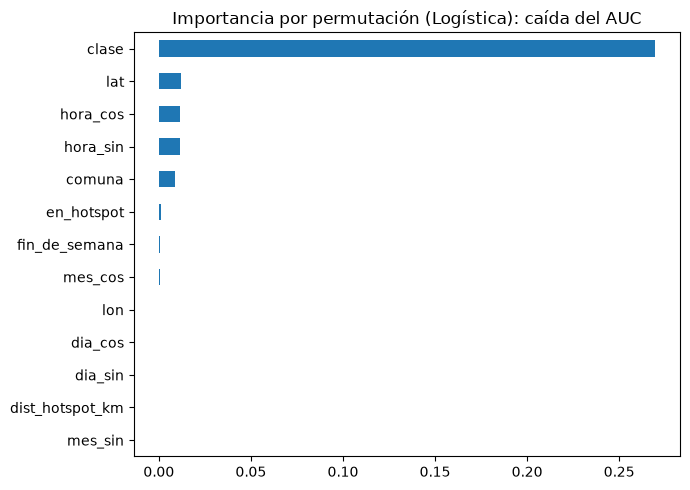

clase              0.2695
lat                0.0120
hora_cos           0.0114
hora_sin           0.0112
comuna             0.0087
en_hotspot         0.0012
fin_de_semana      0.0005
mes_cos            0.0004
lon                0.0003
dia_cos            0.0001
dia_sin            0.0000
dist_hotspot_km   -0.0000
mes_sin           -0.0002
dtype: float64

In [ ]:
muestra = X_test.sample(min(15_000, len(X_test)), random_state=SEED)
pi = permutation_importance(modelos[mejor], muestra, y_test.loc[muestra.index], scoring="roc_auc",
                            n_repeats=3, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=muestra.columns).sort_values()
imp.plot.barh(figsize=(7, 5)); plt.title(f"Importancia por permutación ({mejor}): caída del AUC")
plt.tight_layout(); plt.savefig("outputs/B6_importancia_permutacion.png", dpi=150); plt.show()
imp.sort_values(ascending=False).round(4)

In [ ]:
# Random Forest: importancias del modelo (suman 1) y logística: odds por cada desviación estándar / categoría
rf = modelos["Random Forest"]
nombres = rf.named_steps["prep"].get_feature_names_out()
imp_rf = pd.Series(rf.named_steps["clf"].feature_importances_, index=nombres).sort_values(ascending=False)
print("Random Forest, top 10:"); print(imp_rf.head(10).round(4))

lg = modelos["Logística"]
coef = pd.Series(lg.named_steps["clf"].coef_[0], index=lg.named_steps["prep"].get_feature_names_out())
odds = np.exp(coef).sort_values(ascending=False)
print("\nLogística: odds (e^coef). >1 sube la probabilidad de víctimas; <1 la baja.")
print("Top 8 que más suben:"); print(odds.head(8).round(2))
print("Top 8 que más bajan:"); print(odds.tail(8).round(2))

Random Forest, top 10:
cat__clase_Choque            0.4711
cat__clase_Atropello         0.1266
cat__clase_Caida Ocupante    0.0924
cat__clase_Otro              0.0834
num__lat                     0.0397
num__dist_hotspot_km         0.0330
num__lon                     0.0295
cat__clase_Volcamiento       0.0210
num__hora_cos                0.0206
num__hora_sin                0.0203
dtype: float64

Logística: odds (e^coef). >1 sube la probabilidad de víctimas; <1 la baja.
Top 8 que más suben:
cat__clase_Atropello                                 46.25
cat__clase_Caida Ocupante                            39.52
cat__comuna_Corregimiento de San Antonio de Prado     3.23
cat__clase_Otro                                       1.54
cat__comuna_Guayabal                                  1.49
cat__comuna_Corregimiento de Altavista                1.46
cat__comuna_San Javier                                1.38
cat__comuna_Buenos Aires                              1.30
dtype: float64
Top 8 que más baja

# 8. Comparacion Parte A
Se compara el mismo modelo (boosting) agregando bloques de variables. Si la ubicación y los hotspots de la Parte A mejoran el AUC en la prueba, el enfoque no supervisado aporta al supervisado. Si no mejoran, también es un resultado válido (y honesto).

In [ ]:
def auc_con(num, cat):
    m = Pipeline([("prep", hacer_prep(num, cat)),
                  ("clf", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=SEED))])
    cols = num + cat
    m.fit(X_train[cols], y_train)
    return roc_auc_score(y_test, m.predict_proba(X_test[cols])[:, 1])

ablacion = {
    "1. Solo clase del incidente": ([], ["clase"]),
    "2. + hora, día y mes": (tiempo, ["clase"]),
    "3. + ubicación (lat, lon, comuna)": (tiempo + lugar_num, ["clase", "comuna"]),
    "4. + hotspot de la Parte A": (tiempo + lugar_num + hotspot, ["clase", "comuna"]),
}
abl = pd.Series({k: auc_con(*v) for k, v in ablacion.items()}, name="AUC_test")
abl.round(4)

1. Solo clase del incidente          0.7931
2. + hora, día y mes                 0.8252
3. + ubicación (lat, lon, comuna)    0.8396
4. + hotspot de la Parte A           0.8395
Name: AUC_test, dtype: float64

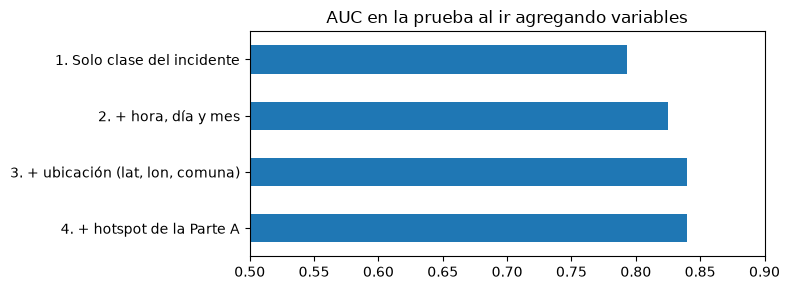

In [ ]:
abl.plot.barh(figsize=(8, 3)); plt.xlim(0.5,0.9)
plt.title("AUC en la prueba al ir agregando variables"); plt.gca().invert_yaxis()
plt.tight_layout(); plt.savefig("outputs/B7_ablacion.png", dpi=150); plt.show()

# 9. Dónde falla el modelo
 AUC por clase de incidente
 
La clase casi decide la gravedad en atropellos y caídas, así que la parte difícil son los choques. El AUC global puede esconder eso.

In [ ]:
por_clase = []
for c in sorted(X_test["clase"].unique()):
    mk = (X_test["clase"] == c).to_numpy()
    yk = y_test.to_numpy()[mk]
    por_clase.append(dict(clase=c, n=int(mk.sum()), tasa_victimas=yk.mean(),
                          AUC=roc_auc_score(yk, p_mejor[mk]) if 0 < yk.sum() < len(yk) and mk.sum() > 50 else np.nan))
tabla_clase = pd.DataFrame(por_clase).set_index("clase").round(3).sort_values("n", ascending=False)
tabla_clase.to_csv("outputs/B10_auc_por_clase.csv")
tabla_clase

,n,tasa_victimas,AUC
clase,,,
Choque,48197,0.397,0.602
Otro,14369,0.990,0.652
Atropello,7258,1.000,NaN
Caida Ocupante,3533,1.000,NaN
Volcamiento,2706,0.977,0.536
Incendio,10,0.500,NaN


In [ ]:
resultados.round(4).to_csv("outputs/B_resultados.csv")
print("Listo. Resultados en outputs/")

Listo. Resultados en outputs/


In [ ]:
#esto se uso como prueba para asegurarnos de los años que estabamos considerando 
print(df.groupby("anio")["con_victimas"].agg(["size", "mean"]).round(3))

       size   mean
anio              
2008  35056  0.379
2009  35140  0.444
2010  35119  0.428
2011  37497  0.440
2012  41929  0.479
2013  45653  0.534
2014  43460  0.561
2015  43869  0.560
2016  45336  0.564
2017  44039  0.544
2018  41359  0.527
2019  43724  0.548
2020  30681  0.595
2021  39113  0.585
2022  36960  0.646
